# Lecture 2 — Class Exercise
# Bar Charts: World Happiness Report 2023

---

> **Your task:** Create **2 polished bar charts** using the World Happiness Report dataset.  
> **Push to:** `week02/lecture02_exercise.ipynb` in **your own GitHub repo** before the end of class.

---

### Rules to keep in mind 💡
1. Every bar chart **must have a zero baseline** — no exceptions
2. Every chart **must have an insight title**, not a topic title
3. Aim for **professional quality** — clean background, readable font, no clutter
4. Horizontal bars for long category names

---


In [2]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

df = pd.read_csv("../data/world_happiness_2023.csv")

df.columns = [
    "Country", "Region", "Happiness_Score", "GDP",
    "Social_Support", "Life_Expectancy", "Freedom",
    "Generosity", "Corruption"
]

print(f"Dataset: {len(df)} countries, {len(df.columns)} columns")
df.head()

Dataset: 63 countries, 9 columns


,Country,Region,Happiness_Score,GDP,Social_Support,Life_Expectancy,Freedom,Generosity,Corruption
0,Finland,Western Europe,7.804,10.775,0.954,71.9,0.949,0.142,0.179
1,Denmark,Western Europe,7.586,10.933,0.954,72.7,0.931,0.168,0.234
2,Iceland,Western Europe,7.525,10.878,0.983,72.5,0.961,0.260,0.150
3,Israel,Middle East and North Africa,7.473,10.527,0.916,72.4,0.903,0.149,0.826
4,Netherlands,Western Europe,7.464,11.015,0.939,72.4,0.879,0.240,0.296


## Setup — Run this cell first


In [3]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import pandas as pd
import numpy as np

# World Happiness Report 2023 — representative data
# Source: https://www.kaggle.com/datasets/ajaypalsinghlo/world-happiness-report-2023

df = pd.read_csv('../data/world_happiness_2023.csv')
df.columns = ['Country','Region','Happiness_Score','GDP','Social_Support',
              'Life_Expectancy','Freedom','Generosity','Corruption']


print(f"Dataset: {len(df)} countries, {len(df.columns)} columns")
df.head()


Dataset: 63 countries, 9 columns


,Country,Region,Happiness_Score,GDP,Social_Support,Life_Expectancy,Freedom,Generosity,Corruption
0,Finland,Western Europe,7.804,10.775,0.954,71.9,0.949,0.142,0.179
1,Denmark,Western Europe,7.586,10.933,0.954,72.7,0.931,0.168,0.234
2,Iceland,Western Europe,7.525,10.878,0.983,72.5,0.961,0.260,0.150
3,Israel,Middle East and North Africa,7.473,10.527,0.916,72.4,0.903,0.149,0.826
4,Netherlands,Western Europe,7.464,11.015,0.939,72.4,0.879,0.240,0.296


In [3]:
import plotly.express as px
import plotly.graph_objects as go

# Explore the dataset before you start
print("Regions in dataset:")
print(df['Region'].value_counts())
print("\nScore range:", df['Happiness_Score'].min(), "–", df['Happiness_Score'].max())
print("\nBottom 10 countries:")
print(df.nsmallest(10, 'Happiness_Score')[['Country','Region','Happiness_Score']])


Regions in dataset:
Region
Western Europe                  15
Latin America and Caribbean     13
Central and Eastern Europe       7
Sub-Saharan Africa               7
Middle East and North Africa     6
North America and ANZ            4
Southeast Asia                   4
South Asia                       4
East Asia                        3
Name: count, dtype: int64

Score range: 1.859 – 7.804

Bottom 10 countries:
        Country                        Region  Happiness_Score
60  Afghanistan                    South Asia            1.859
61      Lebanon  Middle East and North Africa            2.392
62     Zimbabwe            Sub-Saharan Africa            2.995
52     Ethiopia            Sub-Saharan Africa            3.564
53     Tanzania            Sub-Saharan Africa            3.698
48   Bangladesh                    South Asia            3.892
47        India                    South Asia            4.036
50        Kenya            Sub-Saharan Africa            4.112
54       Uganda

---
## Task 1 — Regional Comparison Bar Chart

**What to build:** A horizontal bar chart showing the **average happiness score by region**, sorted from highest to lowest.

**Requirements:**
- Horizontal orientation (category names are long)
- Sorted by score, descending (so the happiest region is at the top)
- Zero baseline on x-axis
- At least one design choice that goes beyond the Plotly default (colour, annotation, labels, etc.)
- An insight title that answers: *which region stands out and why does it matter?*

**Hint:** Use `df.groupby('Region')['Happiness_Score'].mean()` to compute the averages.


                         Region  Happiness_Score
5                    South Asia         3.618250
7            Sub-Saharan Africa         4.064714
3  Middle East and North Africa         4.943333
6                Southeast Asia         5.695250
2   Latin America and Caribbean         5.699000
1                     East Asia         5.966000
0    Central and Eastern Europe         6.338143
4         North America and ANZ         7.018250
8                Western Europe         7.085533


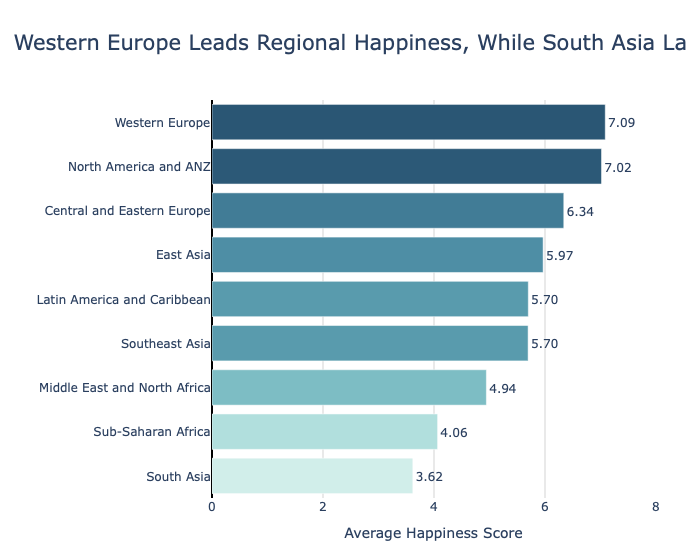

In [4]:
# Task 1: Regional comparison bar chart
# -------------------------------------

# Step 1: Compute average happiness score by region
region_avg = (df.groupby('Region')['Happiness_Score']
              .mean()
              .reset_index()
              .sort_values('Happiness_Score'))  # sort for horizontal bar

print(region_avg)

# Step 2: Build your chart
# YOUR CODE HERE

# Task 1: Regional Comparison Bar Chart

import plotly.express as px

# Step 1: Calculate average happiness score by region
region_avg = (
    df.groupby("Region", as_index=False)["Happiness_Score"]
      .mean()
      .sort_values("Happiness_Score", ascending=False)
)

# Step 2: Create the horizontal bar chart
fig1 = px.bar(
    region_avg,
    x="Happiness_Score",
    y="Region",
    orientation="h",
    text="Happiness_Score",
    color="Happiness_Score",
    color_continuous_scale="Teal",
    title="Western Europe Leads Regional Happiness, While South Asia Lags",
    labels={
        "Happiness_Score": "Average Happiness Score",
        "Region": ""
    }
)

# Step 3: Put the highest-scoring region at the top
fig1.update_layout(
    template="plotly_white",
    title=dict(
        x=0.02,
        xanchor="left",
        font=dict(size=21)
    ),
    xaxis=dict(
        range=[0, 8],
        showgrid=True,
        gridcolor="lightgray",
        zeroline=True,
        zerolinewidth=2,
        zerolinecolor="black"
    ),
    yaxis=dict(
        categoryorder="array",
        categoryarray=region_avg["Region"].tolist()[::-1]
    ),
    coloraxis_showscale=False,
    margin=dict(l=20, r=30, t=100, b=50),
    height=550
)

# Step 4: Display values on the bars
fig1.update_traces(
    texttemplate="%{text:.2f}",
    textposition="outside",
    cliponaxis=False
)

fig1.show()



---
## Task 2 — Bottom vs. Top: A Contrast Story

**What to build:** A bar chart that highlights the **gap between the happiest and least happy countries**, focusing on a specific insight.

**Requirements:**
- Show the **top 8 AND bottom 8 countries** together (16 bars total)
- Use **colour** to distinguish the two groups (not Plotly's default rainbow)
- Add a **visual separator or annotation** that emphasises the gap
- Insight title that tells the story of the gap

**Hint:** Use `pd.concat([df.nlargest(8,'Happiness_Score'), df.nsmallest(8,'Happiness_Score')])` to get both groups.

**Stretch goal:** Add a vertical reference line showing the global average.


Global average: 5.81
Global average happiness score: 5.81


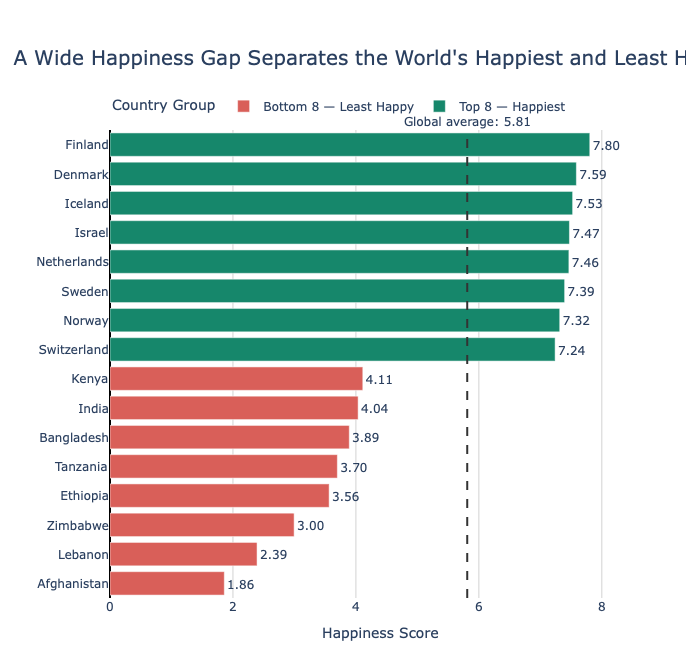

In [5]:
# Task 2: Top 8 vs. Bottom 8 contrast
# ------------------------------------

# Step 1: Get top and bottom countries
top8 = df.nlargest(8, 'Happiness_Score').copy()
top8['Group'] = 'Top 8'
bottom8 = df.nsmallest(8, 'Happiness_Score').copy()
bottom8['Group'] = 'Bottom 8'

combined = pd.concat([bottom8, top8]).sort_values('Happiness_Score')
global_avg = df['Happiness_Score'].mean()
print(f"Global average: {global_avg:.2f}")

# Step 2: Build your chart
# YOUR CODE HERE

# Task 2: Top 8 vs. Bottom 8 Countries

import pandas as pd
import plotly.express as px

# Step 1: Select the top 8 and bottom 8 countries
top8 = df.nlargest(8, "Happiness_Score").copy()
top8["Group"] = "Top 8 — Happiest"

bottom8 = df.nsmallest(8, "Happiness_Score").copy()
bottom8["Group"] = "Bottom 8 — Least Happy"

# Step 2: Combine both groups and sort by happiness score
combined = pd.concat([bottom8, top8], ignore_index=True)
combined = combined.sort_values("Happiness_Score", ascending=True)

# Step 3: Calculate the global average
global_avg = df["Happiness_Score"].mean()

print(f"Global average happiness score: {global_avg:.2f}")

# Step 4: Create the chart with meaningful colors
color_map = {
    "Top 8 — Happiest": "#16876B",
    "Bottom 8 — Least Happy": "#D95F59"
}

fig2 = px.bar(
    combined,
    x="Happiness_Score",
    y="Country",
    orientation="h",
    color="Group",
    color_discrete_map=color_map,
    text="Happiness_Score",
    title="A Wide Happiness Gap Separates the World's Happiest and Least Happy Countries",
    labels={
        "Happiness_Score": "Happiness Score",
        "Country": "",
        "Group": "Country Group"
    },
    category_orders={
        "Country": combined["Country"].tolist(),
        "Group": ["Bottom 8 — Least Happy", "Top 8 — Happiest"]
    }
)

# Step 5: Add a vertical global-average reference line
fig2.add_vline(
    x=global_avg,
    line_dash="dash",
    line_color="#333333",
    line_width=2,
    annotation_text=f"Global average: {global_avg:.2f}",
    annotation_position="top"
)

# Step 6: Polish the chart
fig2.update_layout(
    template="plotly_white",
    title=dict(
        x=0.02,
        xanchor="left",
        font=dict(size=20)
    ),
    xaxis=dict(
        range=[0, 8.8],
        showgrid=True,
        gridcolor="lightgray",
        zeroline=True,
        zerolinewidth=2,
        zerolinecolor="black"
    ),
    yaxis=dict(
        categoryorder="array",
        categoryarray=combined["Country"].tolist()
    ),
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=0
    ),
    margin=dict(l=20, r=35, t=130, b=50),
    height=650
)

fig2.update_traces(
    texttemplate="%{text:.2f}",
    textposition="outside",
    cliponaxis=False
)

fig2.show()




---
## Done? Stretch Goal

If you finish both tasks with time to spare, try this:

**Task 3 (stretch):** Build a **grouped bar chart** comparing 2 sub-factors (e.g. `GDP_per_capita` and `Freedom`) across the 5 most populated regions. Use colour meaningfully and write an insight title.

Regions to include: `'Western Europe'`, `'Latin America'`, `'East Asia'`, `'Sub-Saharan Africa'`, `'South Asia'`


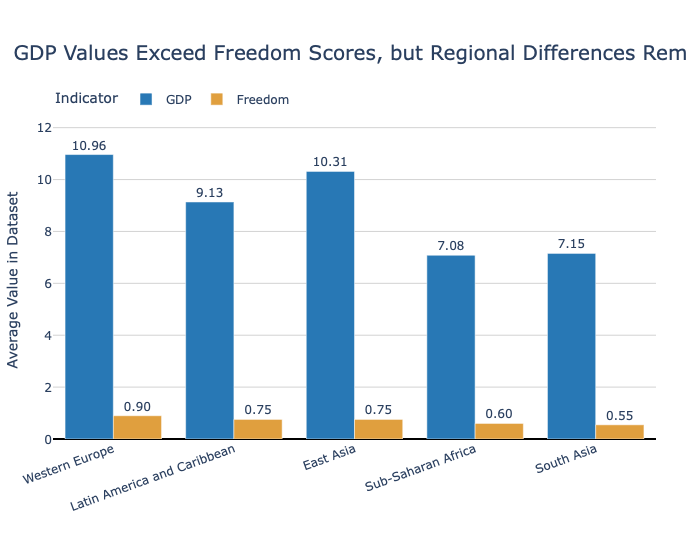

,Region,GDP,Freedom
0,East Asia,10.312000,0.754000
1,Latin America and Caribbean,9.134923,0.754231
2,South Asia,7.152250,0.546250
3,Sub-Saharan Africa,7.082000,0.599429
4,Western Europe,10.963533,0.896067


In [6]:
# Stretch goal — grouped bar chart
# YOUR CODE HERE

# Stretch Goal: Grouped Bar Chart — GDP vs Freedom

import pandas as pd
import plotly.express as px

# Step 1: Select the five regions specified in the assignment
regions = [
    "Western Europe",
    "Latin America and Caribbean",
    "East Asia",
    "Sub-Saharan Africa",
    "South Asia"
]

df_stretch = df[df["Region"].isin(regions)].copy()

# Step 2: Calculate the average GDP and Freedom for each region
region_factors = (
    df_stretch.groupby("Region", as_index=False)
    [["GDP", "Freedom"]]
    .mean()
)

# Step 3: Reshape the data for a grouped bar chart
region_factors_long = region_factors.melt(
    id_vars="Region",
    value_vars=["GDP", "Freedom"],
    var_name="Factor",
    value_name="Average Value"
)

# Step 4: Define meaningful colors
colors = {
    "GDP": "#2878B5",
    "Freedom": "#E09F3E"
}

# Step 5: Build the grouped bar chart
fig3 = px.bar(
    region_factors_long,
    x="Region",
    y="Average Value",
    color="Factor",
    barmode="group",
    text="Average Value",
    color_discrete_map=colors,
    title="GDP Values Exceed Freedom Scores, but Regional Differences Remain",
    labels={
        "Region": "",
        "Average Value": "Average Value in Dataset",
        "Factor": "Indicator"
    },
    category_orders={"Region": regions}
)

# Step 6: Polish the chart
fig3.update_layout(
    template="plotly_white",
    title=dict(
        x=0.02,
        xanchor="left",
        font=dict(size=20)
    ),
    xaxis=dict(
        tickangle=-20
    ),
    yaxis=dict(
        rangemode="tozero",
        zeroline=True,
        zerolinewidth=2,
        zerolinecolor="black",
        showgrid=True,
        gridcolor="lightgray"
    ),
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=0
    ),
    margin=dict(l=30, r=30, t=120, b=100),
    height=550
)

fig3.update_traces(
    texttemplate="%{text:.2f}",
    textposition="outside",
    cliponaxis=False
)

fig3.show()

# Display the averages used in the chart
region_factors

